In [1]:
import ee

ee.Authenticate(auth_mode="colab")
ee.Initialize(project="erimmt")

print("✅ Earth Engine funcionando!")
print("✅ Teste:", ee.Number(10).getInfo())

✅ Earth Engine funcionando!
✅ Teste: 10


In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')

OUTPUT_DIR = '/content/drive/MyDrive/ERIMT_2026_nova_coleta'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("✅ Google Drive conectado!")
print("📁 Pasta de resultados:", OUTPUT_DIR)

Mounted at /content/drive
✅ Google Drive conectado!
📁 Pasta de resultados: /content/drive/MyDrive/ERIMT_2026_nova_coleta


In [3]:

import ee

# Área de estudo: Várzea Grande - MT
CENTER_LON = -56.1326
CENTER_LAT = -15.6461
BUFFER_METERS = 10000

# Período da pesquisa
START_DATE = "2026-01-01"
END_DATE = "2026-06-16"

# Configurações
MAX_CLOUD_PERCENT = 10
TARGET_SCALE = 20

# Delimitação da área
roi = ee.Geometry.Point(
    [CENTER_LON, CENTER_LAT]
).buffer(BUFFER_METERS)

# Coleta Sentinel-2
raw_collection = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(
        ee.Filter.lt(
            "CLOUDY_PIXEL_PERCENTAGE",
            MAX_CLOUD_PERCENT
        )
    )
)

# Conferir imagens disponíveis
n_images = raw_collection.size().getInfo()

print("✅ Coleta consultada!")
print("Imagens Sentinel-2 encontradas:", n_images)
print("Resolução-alvo:", TARGET_SCALE, "metros")

if n_images == 0:
    print("⚠️ Nenhuma imagem encontrada com esses filtros.")

✅ Coleta consultada!
Imagens Sentinel-2 encontradas: 12
Resolução-alvo: 20 metros


In [4]:

import ee

# Bandas que serão utilizadas
FEATURES_5 = ["B2", "B3", "B4", "B8", "B11"]
FEATURES_8 = FEATURES_5 + ["NDVI", "NDWI", "NDBI"]

# Grade de referência: banda B11, 20 metros
ref_projection = ee.Image(
    raw_collection.first()
).select("B11").projection()

# Pré-processamento de cada imagem
def harmonize_scene(img):
    img = ee.Image(img)

    # Remover pixels inválidos, nuvens e sombras
    scl = img.select("SCL")
    valid = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    img = img.updateMask(valid)

    # Agregar bandas de 10 m para 20 m
    bands_20m = (
        img.select(["B2", "B3", "B4", "B8"])
        .reduceResolution(
            reducer=ee.Reducer.mean(),
            maxPixels=16
        )
        .reproject(crs=ref_projection)
    )

    # Alinhar B11 na mesma grade
    b11 = (
        img.select("B11")
        .resample("bilinear")
        .reproject(crs=ref_projection)
    )

    return (
        bands_20m.addBands(b11)
        .copyProperties(img, ["system:time_start"])
    )

# Aplicar às 12 imagens
harmonized_collection = raw_collection.map(harmonize_scene)

# Criar composição temporal por mediana
composite = (
    harmonized_collection
    .median()
    .setDefaultProjection(ref_projection)
    .clip(roi)
)

# Converter reflectância para escala física
reflectance = composite.select(FEATURES_5).divide(10000).toFloat()

# Índices espectrais
ndvi = reflectance.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")

ndwi = reflectance.normalizedDifference(
    ["B3", "B8"]
).rename("NDWI")

ndbi = reflectance.normalizedDifference(
    ["B11", "B8"]
).rename("NDBI")

# Imagem final com oito variáveis
features_image = reflectance.addBands([
    ndvi, ndwi, ndbi
]).toFloat()

print("✅ Harmonização configurada!")
print("✅ Índices espectrais calculados!")
print("Bandas disponíveis:",
      features_image.bandNames().getInfo())
print("Resolução da grade (m):",
      ref_projection.nominalScale().getInfo())


✅ Harmonização configurada!
✅ Índices espectrais calculados!
Bandas disponíveis: ['B2', 'B3', 'B4', 'B8', 'B11', 'NDVI', 'NDWI', 'NDBI']
Resolução da grade (m): 20


In [5]:

import ee

# Bandas que serão utilizadas
FEATURES_5 = ["B2", "B3", "B4", "B8", "B11"]
FEATURES_8 = FEATURES_5 + ["NDVI", "NDWI", "NDBI"]

# Grade de referência: banda B11, 20 metros
ref_projection = ee.Image(
    raw_collection.first()
).select("B11").projection()

# Pré-processamento de cada imagem
def harmonize_scene(img):
    img = ee.Image(img)

    # Remover pixels inválidos, nuvens e sombras
    scl = img.select("SCL")
    valid = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    img = img.updateMask(valid)

    # Agregar bandas de 10 m para 20 m
    bands_20m = (
        img.select(["B2", "B3", "B4", "B8"])
        .reduceResolution(
            reducer=ee.Reducer.mean(),
            maxPixels=16
        )
        .reproject(crs=ref_projection)
    )

    # Alinhar B11 na mesma grade
    b11 = (
        img.select("B11")
        .resample("bilinear")
        .reproject(crs=ref_projection)
    )

    return (
        bands_20m.addBands(b11)
        .copyProperties(img, ["system:time_start"])
    )

# Aplicar às 12 imagens
harmonized_collection = raw_collection.map(harmonize_scene)

# Criar composição temporal por mediana
composite = (
    harmonized_collection
    .median()
    .setDefaultProjection(ref_projection)
    .clip(roi)
)

# Converter reflectância para escala física
reflectance = composite.select(FEATURES_5).divide(10000).toFloat()

# Índices espectrais
ndvi = reflectance.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")

ndwi = reflectance.normalizedDifference(
    ["B3", "B8"]
).rename("NDWI")

ndbi = reflectance.normalizedDifference(
    ["B11", "B8"]
).rename("NDBI")

# Imagem final com oito variáveis
features_image = reflectance.addBands([
    ndvi, ndwi, ndbi
]).toFloat()

print("✅ Harmonização configurada!")
print("✅ Índices espectrais calculados!")
print("Bandas disponíveis:",
      features_image.bandNames().getInfo())
print("Resolução da grade (m):",
      ref_projection.nominalScale().getInfo())


✅ Harmonização configurada!
✅ Índices espectrais calculados!
Bandas disponíveis: ['B2', 'B3', 'B4', 'B8', 'B11', 'NDVI', 'NDWI', 'NDBI']
Resolução da grade (m): 20


In [6]:

# ETAPA 4 - PSEUDO-ROTULAGEM AMBIENTAL

CLASS_NAMES = {
    0: "Área construída",
    1: "Vegetação",
    2: "Água",
    3: "Solo exposto"
}

def build_pseudo_labels(ndvi, ndwi, ndbi):

    # Água
    water = ndwi.gt(0.25)

    # Vegetação
    vegetation = (
        ndvi.gt(0.45)
        .And(water.Not())
    )

    # Área construída
    built = (
        ndbi.gt(0.05)
        .And(ndvi.lt(0.35))
        .And(water.Not())
    )

    # Solo exposto
    bare_soil = (
        ndvi.lt(0.25)
        .And(ndwi.lt(0.10))
        .And(ndbi.lt(0.05))
        .And(water.Not())
    )

    # Pixels sem classificação começam em -1
    pseudo = ee.Image.constant(-1).rename("classe").toInt()

    pseudo = pseudo.where(vegetation, 1)
    pseudo = pseudo.where(water, 2)
    pseudo = pseudo.where(built, 0)
    pseudo = pseudo.where(bare_soil, 3)

    # Manter somente classes válidas
    valid = features_image.mask().reduce(ee.Reducer.min())

    return (
        pseudo.updateMask(pseudo.gte(0))
        .updateMask(valid)
        .clip(roi)
        .toInt()
    )

pseudo_labels = build_pseudo_labels(ndvi, ndwi, ndbi)

print("✅ Pseudo-rótulos configurados!")

# Contagem de pixels em cada classe
histogram = pseudo_labels.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=roi,
    scale=20,
    crs=ref_projection,
    maxPixels=100000000,
    tileScale=4
).get("classe").getInfo()

histogram = histogram or {}

print("\nDISTRIBUIÇÃO DAS CLASSES")
for codigo, nome in CLASS_NAMES.items():
    quantidade = int(histogram.get(str(codigo), 0))
    print(f"{codigo} - {nome}: {quantidade} pixels")


✅ Pseudo-rótulos configurados!

DISTRIBUIÇÃO DAS CLASSES
0 - Área construída: 230502 pixels
1 - Vegetação: 449197 pixels
2 - Água: 10957 pixels
3 - Solo exposto: 15219 pixels


In [7]:

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
N_PER_CLASS = 1000

FEATURES_8 = [
    "B2", "B3", "B4", "B8", "B11",
    "NDVI", "NDWI", "NDBI"
]

# Coordenadas da grade de 20 metros
coords = ee.Image.pixelCoordinates(
    ref_projection
).rename(["px", "py"])

# Preparar imagem para amostragem
sample_image = (
    features_image.select(FEATURES_8)
    .addBands(pseudo_labels)
    .addBands(coords)
)

# Coletar até 1000 pixels por classe
samples = sample_image.stratifiedSample(
    numPoints=N_PER_CLASS,
    classBand="classe",
    classValues=[0, 1, 2, 3],
    classPoints=[1000, 1000, 1000, 1000],
    region=roi,
    scale=20,
    projection=ref_projection,
    seed=SEED,
    dropNulls=True,
    tileScale=4,
    geometries=False
)

# Converter as amostras em tabela
features = samples.getInfo()["features"]

df = pd.DataFrame([
    f["properties"] for f in features
])

df = df.dropna(
    subset=FEATURES_8 + ["classe", "px", "py"]
).copy()

df["classe"] = df["classe"].astype(int)

print("TOTAL DE AMOSTRAS:", len(df))
print("\nAMOSTRAS POR CLASSE:")
print(df["classe"].value_counts().sort_index())

# Definir blocos espaciais de aproximadamente 1 km
# 50 pixels x 20 metros = 1000 metros
BLOCK_PIXELS = 50

df["bloco_x"] = np.floor(
    df["px"] / BLOCK_PIXELS
).astype(int)

df["bloco_y"] = np.floor(
    df["py"] / BLOCK_PIXELS
).astype(int)

df["bloco"] = (
    df["bloco_x"].astype(str)
    + "_"
    + df["bloco_y"].astype(str)
)

# Separação espacial treino/teste
splitter = GroupShuffleSplit(
    n_splits=100,
    test_size=0.25,
    random_state=SEED
)

classes_esperadas = {0, 1, 2, 3}
separacao = None

for train_idx, test_idx in splitter.split(
    df, groups=df["bloco"]
):
    treino = df.iloc[train_idx]
    teste = df.iloc[test_idx]

    ct_treino = treino["classe"].value_counts()
    ct_teste = teste["classe"].value_counts()

    if all(
        ct_treino.get(c, 0) >= 30
        and ct_teste.get(c, 0) >= 30
        for c in classes_esperadas
    ):
        separacao = (train_idx, test_idx)
        break

if separacao is None:
    raise RuntimeError(
        "Não foi possível encontrar uma divisão "
        "espacial com pelo menos 30 amostras "
        "de cada classe em treino e teste."
    )

train_idx, test_idx = separacao

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

# Verificar ausência de blocos compartilhados
assert set(train_df["bloco"]).isdisjoint(
    set(test_df["bloco"])
)

# Salvar os conjuntos
os.makedirs(OUTPUT_DIR, exist_ok=True)

train_df.to_csv(
    os.path.join(OUTPUT_DIR, "treino_espacial.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(OUTPUT_DIR, "teste_espacial.csv"),
    index=False
)

print("\n✅ AMOSTRAGEM CONCLUÍDA")
print("Treinamento:", len(train_df))
print("Teste:", len(test_df))

print("\nDISTRIBUIÇÃO DO TREINAMENTO:")
print(train_df["classe"].value_counts().sort_index())

print("\nDISTRIBUIÇÃO DO TESTE:")
print(test_df["classe"].value_counts().sort_index())

print("\n✅ Nenhum bloco compartilhado entre treino e teste.")
print("✅ Arquivos CSV salvos no Google Drive.")


TOTAL DE AMOSTRAS: 4000

AMOSTRAS POR CLASSE:
classe
0    1000
1    1000
2    1000
3    1000
Name: count, dtype: int64

✅ AMOSTRAGEM CONCLUÍDA
Treinamento: 3048
Teste: 952

DISTRIBUIÇÃO DO TREINAMENTO:
classe
0    775
1    741
2    809
3    723
Name: count, dtype: int64

DISTRIBUIÇÃO DO TESTE:
classe
0    225
1    259
2    191
3    277
Name: count, dtype: int64

✅ Nenhum bloco compartilhado entre treino e teste.
✅ Arquivos CSV salvos no Google Drive.


In [8]:

# =====================================================
# ETAPA 6 - TREINAMENTO MLP-5 E MLP-8
# =====================================================

import os
import random
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

FEATURES_5 = ["B2", "B3", "B4", "B8", "B11"]
FEATURES_8 = FEATURES_5 + ["NDVI", "NDWI", "NDBI"]

os.makedirs(OUTPUT_DIR, exist_ok=True)

# -----------------------------------------------------
# 1. VALIDAÇÃO ESPACIAL INTERNA
# -----------------------------------------------------

splitter_val = GroupShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=SEED
)

divisao = None

for idx_tr, idx_val in splitter_val.split(
    train_df,
    groups=train_df["bloco"]
):
    tr = train_df.iloc[idx_tr]
    val = train_df.iloc[idx_val]

    if all(
        (tr["classe"] == c).sum() >= 30
        and (val["classe"] == c).sum() >= 20
        for c in range(4)
    ):
        divisao = (idx_tr, idx_val)
        break

if divisao is None:
    raise RuntimeError(
        "Não foi encontrada divisão espacial "
        "interna com todas as classes."
    )

idx_tr, idx_val = divisao

dev_train = train_df.iloc[idx_tr].copy()
dev_val = train_df.iloc[idx_val].copy()

assert set(dev_train["bloco"]).isdisjoint(
    set(dev_val["bloco"])
)

print("Treinamento interno:", len(dev_train))
print("Validação espacial:", len(dev_val))
print("Teste independente reservado:", len(test_df))

# -----------------------------------------------------
# 2. ARQUITETURA DA REDE NEURAL
# -----------------------------------------------------

def criar_mlp(n_entradas):

    modelo = tf.keras.Sequential([
        tf.keras.Input(shape=(n_entradas,)),
        tf.keras.layers.Dense(
            64, activation="relu"
        ),
        tf.keras.layers.Dropout(0.20),
        tf.keras.layers.Dense(
            32, activation="relu"
        ),
        tf.keras.layers.Dense(
            4, activation="softmax"
        )
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

# -----------------------------------------------------
# 3. TREINAR E AVALIAR CADA MODELO
# -----------------------------------------------------

resultados = []
modelos = {}
escaladores = {}
historicos = {}

configuracoes = {
    "MLP-5": FEATURES_5,
    "MLP-8": FEATURES_8
}

for nome, colunas in configuracoes.items():

    print("\n" + "=" * 50)
    print("TREINANDO:", nome)
    print("=" * 50)

    # Escalonamento ajustado apenas no treino interno
    scaler = StandardScaler()

    X_train = scaler.fit_transform(
        dev_train[colunas]
    ).astype(np.float32)

    X_val = scaler.transform(
        dev_val[colunas]
    ).astype(np.float32)

    y_train = dev_train["classe"].to_numpy(
        dtype=np.int64
    )

    y_val = dev_val["classe"].to_numpy(
        dtype=np.int64
    )

    # Mesmo ponto inicial aleatório entre modelos
    tf.keras.utils.set_random_seed(SEED)

    modelo = criar_mlp(len(colunas))

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )

    historico = modelo.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    # Avaliar no conjunto de validação
    pred_val = np.argmax(
        modelo.predict(X_val, verbose=0),
        axis=1
    )

    f1_val = f1_score(
        y_val,
        pred_val,
        average="macro",
        zero_division=0
    )

    # Salvar modelo e scaler
    modelo.save(
        os.path.join(OUTPUT_DIR, nome + ".keras")
    )

    joblib.dump(
        scaler,
        os.path.join(OUTPUT_DIR, nome + "_scaler.joblib")
    )

    modelos[nome] = modelo
    escaladores[nome] = scaler
    historicos[nome] = historico.history

    resultados.append({
        "modelo": nome,
        "f1_macro_validacao": f1_val,
        "epocas_executadas": len(
            historico.history["loss"]
        )
    })

    print(
        f"\n✅ {nome} treinada!"
    )
    print(
        f"F1 macro de validação: {f1_val:.4f}"
    )

# -----------------------------------------------------
# 4. SELECIONAR MODELO PELA VALIDAÇÃO
# -----------------------------------------------------

validacao_df = pd.DataFrame(resultados)

melhor_nome = validacao_df.sort_values(
    "f1_macro_validacao",
    ascending=False
).iloc[0]["modelo"]

print("\nRESULTADOS DA VALIDAÇÃO:")
print(validacao_df.to_string(index=False))

print("\nModelo selecionado:", melhor_nome)

# -----------------------------------------------------
# 5. AVALIAÇÃO FINAL NO TESTE ESPACIAL
# -----------------------------------------------------

metricas = []

for nome, colunas in configuracoes.items():

    X_test = escaladores[nome].transform(
        test_df[colunas]
    ).astype(np.float32)

    y_test = test_df["classe"].to_numpy(
        dtype=np.int64
    )

    y_pred = np.argmax(
        modelos[nome].predict(
            X_test, verbose=0
        ),
        axis=1
    )

    metricas.append({
        "modelo": nome,
        "acuracia": accuracy_score(
            y_test, y_pred
        ),
        "acuracia_balanceada": balanced_accuracy_score(
            y_test, y_pred
        ),
        "f1_macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_ponderado": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "kappa": cohen_kappa_score(
            y_test, y_pred
        )
    })

    # Matriz de confusão
    matriz = confusion_matrix(
        y_test, y_pred,
        labels=[0, 1, 2, 3]
    )

    pd.DataFrame(
        matriz,
        index=[
            "Real_0", "Real_1",
            "Real_2", "Real_3"
        ],
        columns=[
            "Pred_0", "Pred_1",
            "Pred_2", "Pred_3"
        ]
    ).to_csv(
        os.path.join(
            OUTPUT_DIR,
            nome + "_matriz_confusao.csv"
        )
    )

    # Relatório de classificação
    relatorio = classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            "Area_construida",
            "Vegetacao",
            "Agua",
            "Solo_exposto"
        ],
        zero_division=0
    )

    with open(
        os.path.join(
            OUTPUT_DIR,
            nome + "_relatorio.txt"
        ),
        "w",
        encoding="utf-8"
    ) as arquivo:
        arquivo.write(relatorio)

# -----------------------------------------------------
# 6. SALVAR MÉTRICAS
# -----------------------------------------------------

metricas_df = pd.DataFrame(metricas)

metricas_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "resumo_metricas_mlp5_mlp8.csv"
    ),
    index=False
)

validacao_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "resumo_validacao_mlp5_mlp8.csv"
    ),
    index=False
)

print("\n✅ TREINAMENTO E AVALIAÇÃO CONCLUÍDOS!")
print("\nMÉTRICAS DO TESTE ESPACIAL:")
print(metricas_df.round(4).to_string(index=False))

print("\nModelo escolhido pela validação:", melhor_nome)
print("\nArquivos salvos em:", OUTPUT_DIR)


Treinamento interno: 2351
Validação espacial: 697
Teste independente reservado: 952

TREINANDO: MLP-5
Epoch 1/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.6512 - loss: 1.1617 - val_accuracy: 0.8824 - val_loss: 0.7949
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8464 - loss: 0.7139 - val_accuracy: 0.8910 - val_loss: 0.4460
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8639 - loss: 0.4633 - val_accuracy: 0.9110 - val_loss: 0.3131
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8877 - loss: 0.3517 - val_accuracy: 0.9268 - val_loss: 0.2479
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9077 - loss: 0.2912 - val_accuracy: 0.9369 - val_loss: 0.2092
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9192 - loss: 0.2531 - val_accuracy: 0.9383 - val_loss: 0.1840
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9324 - loss: 0.2240 - val_accuracy: 0.9484 - val_loss: 0.1637
Epoch 8/

In [9]:

# ETAPA 7 - COMPARAÇÃO COM DYNAMIC WORLD

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report
)

# 1. Carregar referência Dynamic World
dw_collection = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
)

n_dw = dw_collection.size().getInfo()
print("Imagens Dynamic World:", n_dw)

if n_dw == 0:
    raise RuntimeError("Nenhuma imagem Dynamic World encontrada.")

# 2. Harmonizar referência para 20 metros
dw_proj = ee.Image(
    dw_collection.first()
).select("label").projection()

dw_20 = (
    dw_collection.select("label")
    .mode()
    .setDefaultProjection(dw_proj)
    .reduceResolution(
        reducer=ee.Reducer.mode(),
        maxPixels=16
    )
    .reproject(crs=ref_projection)
)

# 3. Converter as 9 classes em 4 classes
# 0 área construída; 1 vegetação;
# 2 água; 3 solo exposto

dw_ref = ee.Image.constant(-1).rename(
    "ref_externa"
).toInt()

dw_ref = dw_ref.where(dw_20.eq(6), 0)

vegetacao_dw = (
    dw_20.eq(1)
    .Or(dw_20.eq(2))
    .Or(dw_20.eq(3))
    .Or(dw_20.eq(4))
    .Or(dw_20.eq(5))
)

dw_ref = dw_ref.where(vegetacao_dw, 1)
dw_ref = dw_ref.where(dw_20.eq(0), 2)
dw_ref = dw_ref.where(dw_20.eq(7), 3)

dw_ref = (
    dw_ref.updateMask(dw_20.mask())
    .updateMask(dw_ref.gte(0))
    .clip(roi)
)

# 4. Preparar amostragem e blocos
coords_dw = ee.Image.pixelCoordinates(
    ref_projection
).rename(["px", "py"])

stack_dw = (
    features_image.select(FEATURES_8)
    .addBands(dw_ref)
    .addBands(coords_dw)
)

fc_dw = stack_dw.stratifiedSample(
    numPoints=1000,
    classBand="ref_externa",
    classValues=[0, 1, 2, 3],
    classPoints=[1000, 1000, 1000, 1000],
    region=roi,
    scale=20,
    projection=ref_projection,
    seed=99,
    dropNulls=True,
    tileScale=4,
    geometries=False
)

df_dw = pd.DataFrame([
    f["properties"]
    for f in fc_dw.getInfo()["features"]
])

# 5. Manter somente blocos reservados para teste
BLOCK_PIXELS = 50

df_dw["bloco_x"] = np.floor(
    df_dw["px"] / BLOCK_PIXELS
).astype(int)

df_dw["bloco_y"] = np.floor(
    df_dw["py"] / BLOCK_PIXELS
).astype(int)

df_dw["bloco"] = (
    df_dw["bloco_x"].astype(str)
    + "_"
    + df_dw["bloco_y"].astype(str)
)

externo = df_dw[
    df_dw["bloco"].isin(test_df["bloco"])
].copy()

if externo.empty:
    raise RuntimeError(
        "Nenhuma amostra do Dynamic World "
        "nos blocos espaciais de teste."
    )

print("\nAMOSTRAS DA REFERÊNCIA EXTERNA:")
print(externo["ref_externa"].value_counts().sort_index())

# 6. Comparar os dois modelos
resultados_dw = []

for nome, colunas in configuracoes.items():

    X = escaladores[nome].transform(
        externo[colunas]
    ).astype(np.float32)

    y_real = externo["ref_externa"].astype(int).to_numpy()

    y_pred = np.argmax(
        modelos[nome].predict(X, verbose=0),
        axis=1
    )

    resultados_dw.append({
        "modelo": nome,
        "amostras": len(externo),
        "acuracia": accuracy_score(y_real, y_pred),
        "acuracia_balanceada": balanced_accuracy_score(
            y_real, y_pred
        ),
        "f1_macro": f1_score(
            y_real, y_pred,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "kappa": cohen_kappa_score(y_real, y_pred)
    })

    print("\n", nome, "× DYNAMIC WORLD")
    print(classification_report(
        y_real, y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            "Area_construida", "Vegetacao",
            "Agua", "Solo_exposto"
        ],
        zero_division=0
    ))

    resultado = externo.copy()
    resultado["predicao"] = y_pred

    resultado.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"validacao_dynamicworld_{nome}.csv"
        ),
        index=False
    )

# 7. Salvar resumo
resultados_dw_df = pd.DataFrame(resultados_dw)

resultados_dw_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "resumo_comparacao_dynamicworld.csv"
    ),
    index=False
)

print("\n✅ COMPARAÇÃO COM DYNAMIC WORLD CONCLUÍDA!")
print(resultados_dw_df.round(4).to_string(index=False))

if set(externo["ref_externa"].astype(int)) != {0, 1, 2, 3}:
    print(
        "\n⚠️ Nem todas as classes estão presentes. "
        "Interprete o F1-macro com cautela."
    )

print("\n✅ Resultados salvos no Google Drive!")


Imagens Dynamic World: 23

AMOSTRAS DA REFERÊNCIA EXTERNA:
ref_externa
0    200
1    267
2    175
3    381
Name: count, dtype: int64

 MLP-5 × DYNAMIC WORLD
                 precision    recall  f1-score   support

Area_construida       0.25      0.67      0.37       200
      Vegetacao       0.76      0.92      0.83       267
           Agua       1.00      0.61      0.75       175
   Solo_exposto       0.22      0.04      0.07       381

       accuracy                           0.49      1023
      macro avg       0.56      0.56      0.51      1023
   weighted avg       0.50      0.49      0.44      1023


 MLP-8 × DYNAMIC WORLD
                 precision    recall  f1-score   support

Area_construida       0.26      0.67      0.37       200
      Vegetacao       0.74      0.92      0.82       267
           Agua       1.00      0.61      0.76       175
   Solo_exposto       0.25      0.04      0.07       381

       accuracy                           0.49      1023
      macro avg 


MATRIZ DE CONFUSÃO: MLP-5
                 Área construída  Vegetação  Água  Solo exposto
Área construída              133         48     0            19
Vegetação                     21        245     0             1
Água                           4         28   106            37
Solo exposto                 364          1     0            16

PREDIÇÕES POR CLASSE:
0    522
1    322
2    106
3     73
Name: count, dtype: int64


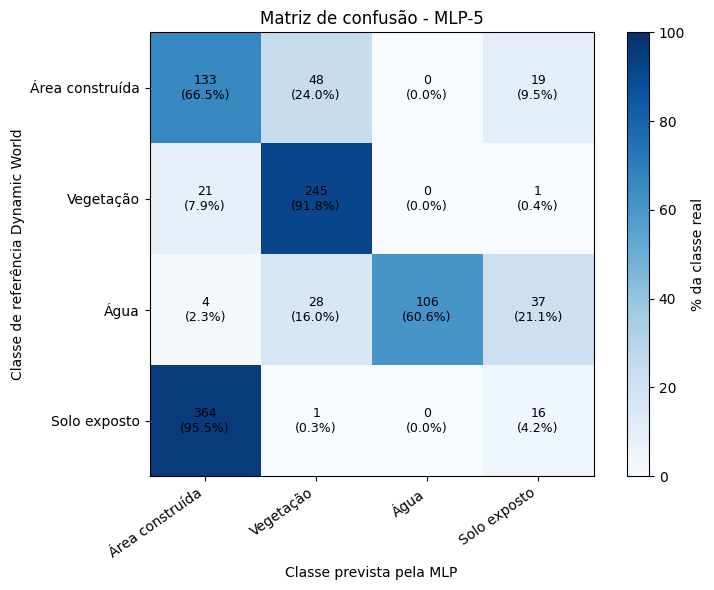


MATRIZ DE CONFUSÃO: MLP-8
                 Área construída  Vegetação  Água  Solo exposto
Área construída              133         49     0            18
Vegetação                     21        246     0             0
Água                           3         35   107            30
Solo exposto                 364          1     0            16

PREDIÇÕES POR CLASSE:
0    521
1    331
2    107
3     64
Name: count, dtype: int64


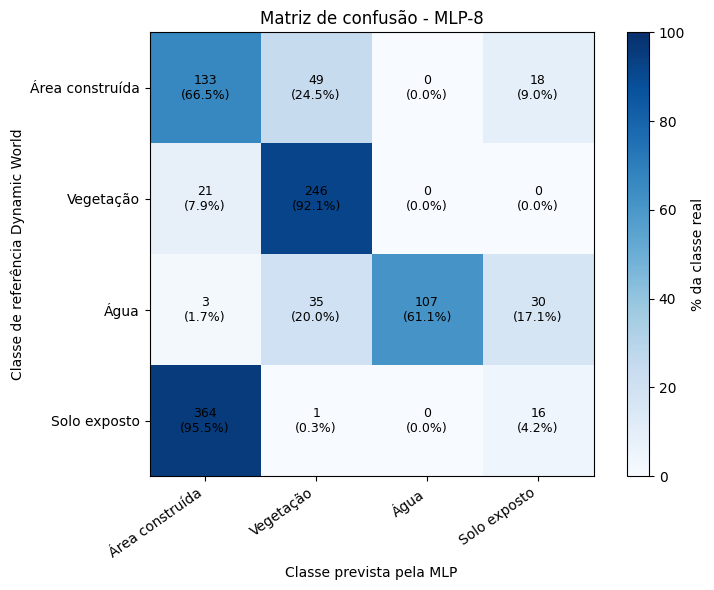


✅ Diagnóstico concluído!
✅ Matrizes e gráficos salvos no Google Drive.


In [10]:

# ETAPA 8 - DIAGNÓSTICO DE ERROS

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

NOMES = [
    "Área construída",
    "Vegetação",
    "Água",
    "Solo exposto"
]

y_real = externo["ref_externa"].astype(int).to_numpy()

for nome, colunas in configuracoes.items():

    X = escaladores[nome].transform(
        externo[colunas]
    ).astype(np.float32)

    y_pred = np.argmax(
        modelos[nome].predict(X, verbose=0),
        axis=1
    )

    matriz = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1, 2, 3]
    )

    matriz_df = pd.DataFrame(
        matriz,
        index=NOMES,
        columns=NOMES
    )

    print("\n" + "=" * 55)
    print("MATRIZ DE CONFUSÃO:", nome)
    print("=" * 55)
    print(matriz_df)

    print("\nPREDIÇÕES POR CLASSE:")
    print(pd.Series(y_pred).value_counts().sort_index())

    # Porcentagem de cada classe real
    matriz_pct = (
        matriz_df.div(
            matriz_df.sum(axis=1),
            axis=0
        ) * 100
    ).fillna(0)

    # Gráfico
    fig, ax = plt.subplots(figsize=(8, 6))

    im = ax.imshow(matriz_pct, cmap="Blues", vmin=0, vmax=100)

    ax.set_xticks(range(4), NOMES, rotation=35, ha="right")
    ax.set_yticks(range(4), NOMES)

    ax.set_xlabel("Classe prevista pela MLP")
    ax.set_ylabel("Classe de referência Dynamic World")
    ax.set_title(f"Matriz de confusão - {nome}")

    for i in range(4):
        for j in range(4):
            ax.text(
                j, i,
                f"{matriz[i, j]}\n({matriz_pct.iloc[i, j]:.1f}%)",
                ha="center",
                va="center",
                fontsize=9
            )

    fig.colorbar(im, ax=ax, label="% da classe real")
    plt.tight_layout()

    # Salvar tabela e figura
    matriz_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"matriz_dynamicworld_{nome}.csv"
        ),
        encoding="utf-8-sig"
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"matriz_dynamicworld_{nome}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\n✅ Diagnóstico concluído!")
print("✅ Matrizes e gráficos salvos no Google Drive.")


In [11]:

# ETAPA 9 - DIAGNÓSTICO ESPECTRAL
import os
import numpy as np
import pandas as pd

diagnostico = externo.copy()

# Recuperar previsões da MLP-8
X = escaladores["MLP-8"].transform(
    diagnostico[FEATURES_8]
).astype(np.float32)

diagnostico["pred_mlp8"] = np.argmax(
    modelos["MLP-8"].predict(X, verbose=0),
    axis=1
)

# Grupo de maior divergência
confusos = diagnostico[
    (diagnostico["ref_externa"] == 3) &
    (diagnostico["pred_mlp8"] == 0)
].copy()

# Regras originais de pseudo-rotulagem
agua = confusos["NDWI"] > 0.25

regra_construida = (
    (confusos["NDBI"] > 0.05) &
    (confusos["NDVI"] < 0.35) &
    (~agua)
)

regra_solo = (
    (confusos["NDVI"] < 0.25) &
    (confusos["NDWI"] < 0.10) &
    (confusos["NDBI"] < 0.05) &
    (~agua)
)

print("DIAGNÓSTICO DA DIVERGÊNCIA")
print("=" * 50)
print("Solo exposto confundido com área construída:",
      len(confusos))

print("Atendem à regra de área construída:",
      int(regra_construida.sum()))

print("Atendem à regra de solo exposto:",
      int(regra_solo.sum()))

# Estatísticas por grupo
grupos = {
    "Solo DW previsto como construção": confusos,
    "Solo DW corretamente previsto": diagnostico[
        (diagnostico["ref_externa"] == 3) &
        (diagnostico["pred_mlp8"] == 3)
    ],
    "Área construída DW": diagnostico[
        diagnostico["ref_externa"] == 0
    ]
}

for nome, grupo in grupos.items():
    print("\n" + nome)
    print("Amostras:", len(grupo))
    print(
        grupo[["NDVI", "NDWI", "NDBI"]]
        .describe()
        .loc[["25%", "50%", "75%"]]
        .round(4)
    )

# Salvar diagnóstico no Google Drive
diagnostico.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "diagnostico_espectral_completo.csv"
    ),
    index=False
)

confusos.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "solo_confundido_com_construcao.csv"
    ),
    index=False
)

print("\n✅ Diagnóstico espectral concluído!")
print("✅ Arquivos salvos no Google Drive.")


DIAGNÓSTICO DA DIVERGÊNCIA
Solo exposto confundido com área construída: 364
Atendem à regra de área construída: 362
Atendem à regra de solo exposto: 0

Solo DW previsto como construção
Amostras: 364
       NDVI    NDWI    NDBI
25%  0.0386 -0.3215  0.1298
50%  0.0596 -0.2603  0.1755
75%  0.1123 -0.2046  0.2372

Solo DW corretamente previsto
Amostras: 16
       NDVI    NDWI    NDBI
25%  0.1611 -0.3208 -0.0037
50%  0.2215 -0.3066  0.0282
75%  0.2562 -0.2489  0.0483

Área construída DW
Amostras: 200
       NDVI    NDWI    NDBI
25%  0.1021 -0.4575  0.0342
50%  0.1980 -0.3094  0.1238
75%  0.3785 -0.2039  0.1796

✅ Diagnóstico espectral concluído!
✅ Arquivos salvos no Google Drive.


In [12]:

# ETAPA 10 - AUDITORIA DA DIVERGÊNCIA

import os
import pandas as pd
import ee

# Probabilidades medianas temporais do Dynamic World
prob_dw = (
    dw_collection
    .select(["bare", "built"])
    .median()
    .rename(["prob_solo", "prob_construcao"])
)

# Discordância entre a referência e a regra
discordancia = (
    dw_ref.eq(3)
    .And(pseudo_labels.eq(0))
    .selfMask()
)

# Preparar variáveis e coordenadas geográficas
auditoria_imagem = (
    ee.Image.constant(1)
    .rename("grupo")
    .updateMask(discordancia)
    .addBands(ee.Image.pixelLonLat())
    .addBands(
        features_image.select(
            ["NDVI", "NDWI", "NDBI"]
        )
    )
    .addBands(prob_dw)
)

# Selecionar 30 pontos de discordância
pontos = auditoria_imagem.stratifiedSample(
    numPoints=30,
    classBand="grupo",
    region=roi,
    scale=20,
    projection=ref_projection,
    seed=321,
    tileScale=4,
    geometries=False,
    dropNulls=True
)

dados = pontos.getInfo()["features"]

if not dados:
    raise RuntimeError(
        "Nenhum ponto disponível para auditoria."
    )

df_auditoria = pd.DataFrame(
    [p["properties"] for p in dados]
)

# Estatísticas das probabilidades
print("PONTOS DE AUDITORIA:", len(df_auditoria))

print("\nPROBABILIDADES MEDIANAS TEMPORAIS:")
print(
    df_auditoria[
        ["prob_solo", "prob_construcao"]
    ].median().round(4)
)

print("\nPONTOS COM PROBABILIDADE MEDIANA DE SOLO >= 0.5:")
print(
    (df_auditoria["prob_solo"] >= 0.5).sum()
)

print("\nPONTOS COM PROBABILIDADE MEDIANA DE CONSTRUÇÃO >= 0.5:")
print(
    (df_auditoria["prob_construcao"] >= 0.5).sum()
)

# Criar links para inspeção geográfica
df_auditoria["link_mapa"] = df_auditoria.apply(
    lambda r: (
        "https://www.google.com/maps/"
        f"@{r['latitude']},{r['longitude']},18z"
    ),
    axis=1
)

# Salvar resultados
caminho = os.path.join(
    OUTPUT_DIR,
    "auditoria_solo_construcao_30_pontos.csv"
)

df_auditoria.to_csv(
    caminho,
    index=False,
    encoding="utf-8-sig"
)

print("\n✅ Auditoria preparada!")
print("✅ Arquivo salvo:", caminho)

print("\nPRIMEIROS PONTOS:")
print(
    df_auditoria[
        ["latitude", "longitude",
         "prob_solo", "prob_construcao"]
    ].head().round(4)
)


PONTOS DE AUDITORIA: 30

PROBABILIDADES MEDIANAS TEMPORAIS:
prob_solo          0.4022
prob_construcao    0.0882
dtype: float64

PONTOS COM PROBABILIDADE MEDIANA DE SOLO >= 0.5:
7

PONTOS COM PROBABILIDADE MEDIANA DE CONSTRUÇÃO >= 0.5:
0

✅ Auditoria preparada!
✅ Arquivo salvo: /content/drive/MyDrive/ERIMT_2026_nova_coleta/auditoria_solo_construcao_30_pontos.csv

PRIMEIROS PONTOS:
   latitude  longitude  prob_solo  prob_construcao
0  -15.5708   -56.1672     0.5459           0.0875
1  -15.6729   -56.2015     0.4017           0.0435
2  -15.5886   -56.1560     0.5106           0.0853
3  -15.5990   -56.1785     0.3485           0.1586
4  -15.5697   -56.1805     0.4002           0.1037


In [14]:

# ETAPA 11 - ESTABILIDADE TEMPORAL DOS ROTULOS

import ee
import os
import pandas as pd

BANDAS_PROB = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built",
    "bare", "snow_and_ice"
]

# Indicadores para cada cena Dynamic World
def indicadores_cena(imagem):
    imagem = ee.Image(imagem)
    rotulo = imagem.select("label")

    maior_prob = (
        imagem.select(BANDAS_PROB)
        .reduce(ee.Reducer.max())
        .rename("prob_vencedora")
    )

    return ee.Image.cat([
        rotulo.eq(7).rename("voto_solo"),
        rotulo.eq(6).rename("voto_construcao"),
        maior_prob
    ])

serie = dw_collection.map(indicadores_cena)

# Estatisticas temporais
imagem_temporal = ee.Image.cat([
    serie.select("voto_solo")
        .mean()
        .rename("frequencia_solo"),

    serie.select("voto_construcao")
        .mean()
        .rename("frequencia_construcao"),

    serie.select("prob_vencedora")
        .median()
        .rename("confianca_mediana_top1"),

    dw_collection.select("label")
        .count()
        .rename("cenas_validas")
])

# Reutilizar os 30 pontos da auditoria
base = df_auditoria.reset_index(drop=True).copy()
base["id_ponto"] = range(len(base))

pontos_ee = ee.FeatureCollection([
    ee.Feature(
        ee.Geometry.Point([
            float(linha["longitude"]),
            float(linha["latitude"])
        ]),
        {"id_ponto": int(linha["id_ponto"])}
    )
    for _, linha in base.iterrows()
])

# Consultar os indicadores nos pontos
resultado = imagem_temporal.sampleRegions(
    collection=pontos_ee,
    scale=20,
    projection=ref_projection,
    geometries=False,
    tileScale=4
)

dados = [
    item["properties"]
    for item in resultado.getInfo()["features"]
]

df_temporal = pd.DataFrame(dados)

if df_temporal.empty:
    raise RuntimeError(
        "Nenhum dado temporal encontrado nos pontos."
    )

# Juntar com a auditoria anterior
auditoria_final = base.merge(
    df_temporal,
    on="id_ponto",
    how="left"
)

print("PONTOS ANALISADOS:", len(df_temporal))

print("\nMEDIANAS TEMPORAIS:")
print(
    auditoria_final[
        [
            "frequencia_solo",
            "frequencia_construcao",
            "confianca_mediana_top1",
            "cenas_validas"
        ]
    ].median().round(4)
)

print("\nSOLO EM PELO MENOS 75% DAS CENAS:")
print(
    (auditoria_final["frequencia_solo"] >= 0.75).sum()
)

print("\nCONSTRUCAO EM PELO MENOS 75% DAS CENAS:")
print(
    (auditoria_final["frequencia_construcao"] >= 0.75).sum()
)

# Salvar para analise posterior
caminho = os.path.join(
    OUTPUT_DIR,
    "auditoria_estabilidade_temporal.csv"
)

auditoria_final.to_csv(
    caminho,
    index=False,
    encoding="utf-8-sig"
)

print("\n✅ Auditoria temporal concluida!")
print("✅ Arquivo salvo:", caminho)


PONTOS ANALISADOS: 30

MEDIANAS TEMPORAIS:
frequencia_solo           0.8750
frequencia_construcao     0.0000
confianca_mediana_top1    0.4138
cenas_validas             7.0000
dtype: float64

SOLO EM PELO MENOS 75% DAS CENAS:
24

CONSTRUCAO EM PELO MENOS 75% DAS CENAS:
0

✅ Auditoria temporal concluida!
✅ Arquivo salvo: /content/drive/MyDrive/ERIMT_2026_nova_coleta/auditoria_estabilidade_temporal.csv


In [18]:

# =====================================================
# ETAPA 12 - MAPA INTERATIVO CORRIGIDO
# ERIMMT 2026 - VÁRZEA GRANDE / MT
# =====================================================

import ee
import folium
import pandas as pd
import os
from IPython.display import display

# 1. Selecionar pontos para inspeção
pontos_revisao = auditoria_final[
    (auditoria_final["frequencia_solo"] >= 0.75) &
    (auditoria_final["cenas_validas"] >= 5)
].copy()

print("Pontos selecionados:", len(pontos_revisao))

# 2. Criar mapa Folium
mapa = folium.Map(
    location=[CENTER_LAT, CENTER_LON],
    zoom_start=12,
    tiles="OpenStreetMap",
    control_scale=True
)

# 3. Função para adicionar imagens Earth Engine
def adicionar_camada_ee(
    mapa, imagem, visualizacao, nome,
    mostrar=True, opacidade=1.0
):
    mapa_id = ee.Image(imagem).getMapId(
        visualizacao
    )

    folium.raster_layers.TileLayer(
        tiles=mapa_id["tile_fetcher"].url_format,
        attr="Google Earth Engine",
        name=nome,
        overlay=True,
        control=True,
        show=mostrar,
        opacity=opacidade
    ).add_to(mapa)

# 4. Sentinel-2 RGB
adicionar_camada_ee(
    mapa,
    reflectance,
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0.02,
        "max": 0.35
    },
    "Sentinel-2 RGB",
    True
)

# 5. Cores das quatro classes
cores = [
    "E45756",  # Área construída
    "39A45B",  # Vegetação
    "3985D7",  # Água
    "D8AD64"   # Solo exposto
]

# 6. Pseudo-rótulos originais
adicionar_camada_ee(
    mapa,
    pseudo_labels,
    {
        "min": 0,
        "max": 3,
        "palette": cores
    },
    "Pseudo-rótulos",
    False,
    0.65
)

# 7. Dynamic World
adicionar_camada_ee(
    mapa,
    dw_ref,
    {
        "min": 0,
        "max": 3,
        "palette": cores
    },
    "Dynamic World",
    False,
    0.65
)

# 8. Adicionar pontos de discordância
grupo = folium.FeatureGroup(
    name="Pontos de discordância",
    show=True
)

for _, linha in pontos_revisao.iterrows():

    lat = float(linha["latitude"])
    lon = float(linha["longitude"])
    freq = float(linha["frequencia_solo"])
    n_cenas = int(linha["cenas_validas"])
    id_ponto = int(linha["id_ponto"])

    texto = (
        f"Ponto {id_ponto}<br>"
        f"Frequência de solo: {freq:.1%}<br>"
        f"Cenas válidas: {n_cenas}"
    )

    folium.CircleMarker(
        location=[lat, lon],
        radius=6,
        color="#FF00FF",
        weight=2,
        fill=True,
        fill_color="#FF00FF",
        fill_opacity=0.8,
        popup=folium.Popup(
            texto, max_width=280
        )
    ).add_to(grupo)

grupo.add_to(mapa)

# 9. Controle de camadas
folium.LayerControl(
    collapsed=False
).add_to(mapa)

# 10. Exibir mapa
print("✅ Mapa interativo configurado!")
display(mapa)

# 11. Salvar HTML no Google Drive
caminho = os.path.join(
    OUTPUT_DIR,
    "mapa_auditoria_erimmt_2026.html"
)

mapa.save(caminho)

print("✅ Mapa HTML salvo em:", caminho)

# 12. Mostrar pontos
display(
    pontos_revisao[
        [
            "id_ponto",
            "latitude",
            "longitude",
            "frequencia_solo",
            "cenas_validas"
        ]
    ].round(4)
)



Pontos selecionados: 24
✅ Mapa interativo configurado!


✅ Mapa HTML salvo em: /content/drive/MyDrive/ERIMT_2026_nova_coleta/mapa_auditoria_erimmt_2026.html


,id_ponto,latitude,longitude,frequencia_solo,cenas_validas
0,0,-15.5708,-56.1672,1.0000,8
2,2,-15.5886,-56.1560,1.0000,8
3,3,-15.5990,-56.1785,0.8750,8
4,4,-15.5697,-56.1805,0.9000,10
5,5,-15.6768,-56.2045,1.0000,8
6,6,-15.6178,-56.1756,0.8571,7
7,7,-15.5641,-56.1309,0.8571,7
8,8,-15.5643,-56.1309,0.8571,7
9,9,-15.7052,-56.1979,0.8571,7
10,10,-15.5994,-56.1813,1.0000,8


In [19]:

# ETAPA 12 - MAPA SEM OPENSTREETMAP

import ee
import folium
import os
from IPython.display import display

# Criar mapa SEM serviço externo de fundo
mapa = folium.Map(
    location=[CENTER_LAT, CENTER_LON],
    zoom_start=12,
    tiles=None,
    control_scale=True
)

# Função para adicionar imagens do Earth Engine
def add_ee_layer(imagem, params, nome, mostrar=True):
    dados = ee.Image(imagem).getMapId(params)

    folium.raster_layers.TileLayer(
        tiles=dados["tile_fetcher"].url_format,
        attr="Google Earth Engine",
        name=nome,
        overlay=True,
        control=True,
        show=mostrar,
        opacity=0.75 if nome != "Sentinel-2 RGB" else 1
    ).add_to(mapa)

# Imagem Sentinel-2
add_ee_layer(
    reflectance,
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0.02,
        "max": 0.35
    },
    "Sentinel-2 RGB"
)

cores = ["E45756", "39A45B", "3985D7", "D8AD64"]

# Classificações
add_ee_layer(
    pseudo_labels,
    {"min": 0, "max": 3, "palette": cores},
    "Pseudo-rótulos",
    False
)

add_ee_layer(
    dw_ref,
    {"min": 0, "max": 3, "palette": cores},
    "Dynamic World",
    False
)

# Pontos auditados
grupo = folium.FeatureGroup(
    name="24 pontos de auditoria"
)

for _, linha in pontos_revisao.iterrows():
    folium.CircleMarker(
        location=[
            float(linha["latitude"]),
            float(linha["longitude"])
        ],
        radius=6,
        color="#FF00FF",
        fill=True,
        fill_opacity=0.85,
        popup=(
            f"Ponto {int(linha['id_ponto'])}"
            f" | Solo: {linha['frequencia_solo']:.1%}"
        )
    ).add_to(grupo)

grupo.add_to(mapa)

folium.LayerControl(
    collapsed=False
).add_to(mapa)

display(mapa)

# Salvar versão corrigida
arquivo = os.path.join(
    OUTPUT_DIR,
    "mapa_auditoria_erimmt_sem_bloqueio.html"
)

mapa.save(arquivo)

print("✅ Mapa corrigido!")
print("✅ Pontos:", len(pontos_revisao))
print("✅ Arquivo salvo:", arquivo)


✅ Mapa corrigido!
✅ Pontos: 24
✅ Arquivo salvo: /content/drive/MyDrive/ERIMT_2026_nova_coleta/mapa_auditoria_erimmt_sem_bloqueio.html


✅ Imagem ampliada gerada!
Ponto: 0
Latitude: -15.570756648425236
Longitude: -56.16722822503907
Arquivo: /content/drive/MyDrive/ERIMT_2026_nova_coleta/ponto_0_sentinel2_ampliado.png


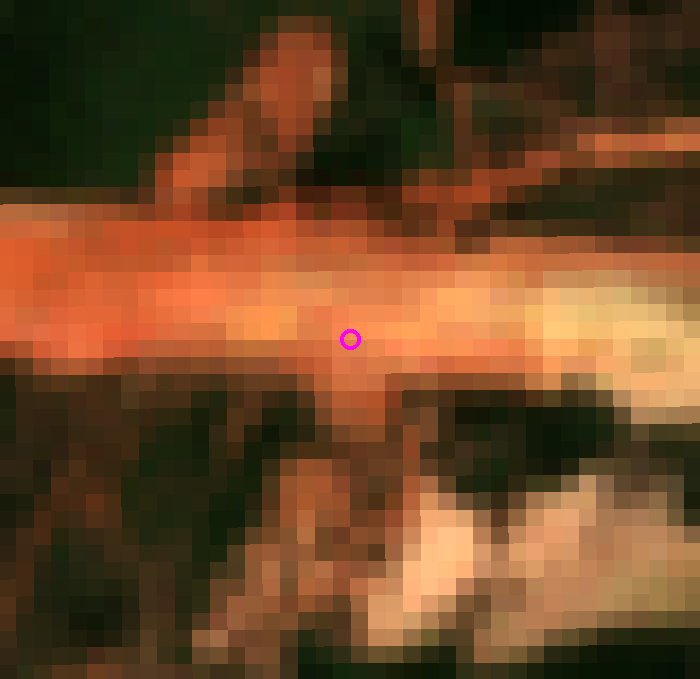

In [20]:

# ETAPA 13 - RECORTE SATELITAL DO PONTO 0

import ee
import requests
import os
from PIL import Image, ImageDraw
from io import BytesIO
from IPython.display import display

ID_PONTO = 0

# Localizar o ponto
ponto = pontos_revisao[
    pontos_revisao["id_ponto"] == ID_PONTO
].iloc[0]

lat = float(ponto["latitude"])
lon = float(ponto["longitude"])

# Área de 200 metros ao redor
area = ee.Geometry.Point(
    [lon, lat]
).buffer(200).bounds()

# Preparar composição RGB com máscara de nuvens
def preparar_rgb(img):
    scl = img.select("SCL")

    mascara = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return (
        img.updateMask(mascara)
        .select(["B4", "B3", "B2"])
        .divide(10000)
    )

rgb = raw_collection.map(preparar_rgb).median()

# Gerar imagem ampliada
url = rgb.getThumbURL({
    "bands": ["B4", "B3", "B2"],
    "min": 0.02,
    "max": 0.35,
    "region": area,
    "dimensions": 700,
    "format": "png"
})

resposta = requests.get(url, timeout=90)
resposta.raise_for_status()

imagem = Image.open(
    BytesIO(resposta.content)
).convert("RGB")

# Marcar aproximadamente o centro
desenho = ImageDraw.Draw(imagem)
cx, cy = imagem.width // 2, imagem.height // 2

desenho.ellipse(
    (cx-10, cy-10, cx+10, cy+10),
    outline="magenta",
    width=4
)

# Salvar no Google Drive
caminho = os.path.join(
    OUTPUT_DIR,
    "ponto_0_sentinel2_ampliado.png"
)

imagem.save(caminho)

print("✅ Imagem ampliada gerada!")
print("Ponto:", ID_PONTO)
print("Latitude:", lat)
print("Longitude:", lon)
print("Arquivo:", caminho)

display(imagem)



PONTO: 5
Latitude: -15.676842950540815
Longitude: -56.204496271313744
Frequência de solo: 100.0%


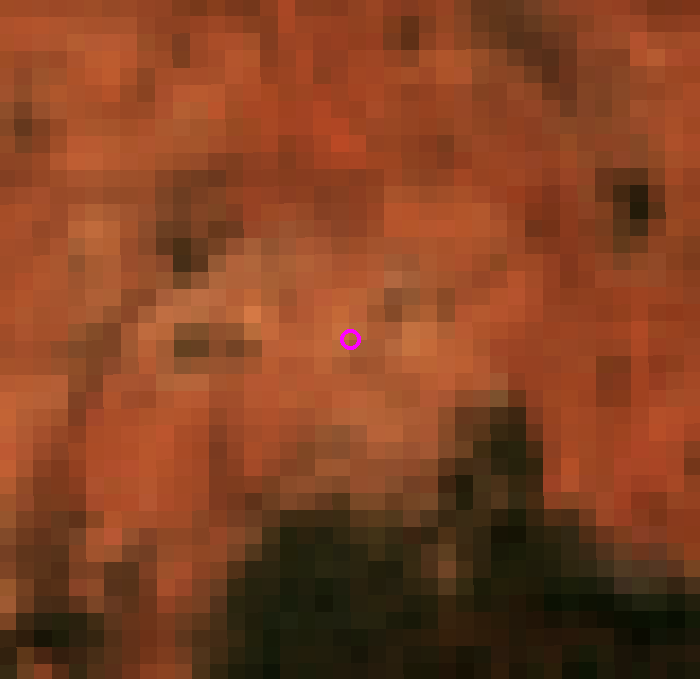

Salvo em: /content/drive/MyDrive/ERIMT_2026_nova_coleta/auditoria_ponto_5.png

PONTO: 14
Latitude: -15.69908739674324
Longitude: -56.112211627388255
Frequência de solo: 85.7%


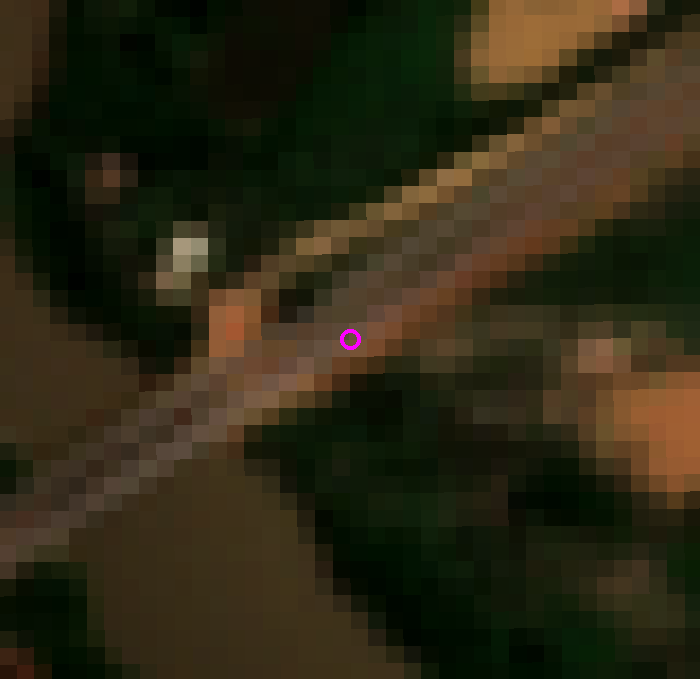

Salvo em: /content/drive/MyDrive/ERIMT_2026_nova_coleta/auditoria_ponto_14.png

PONTO: 21
Latitude: -15.693771734966205
Longitude: -56.09450484401535
Frequência de solo: 100.0%


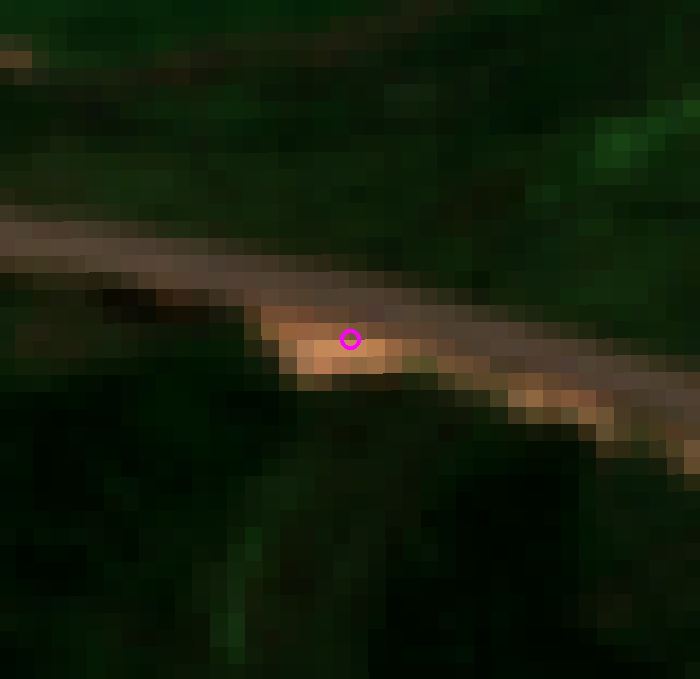

Salvo em: /content/drive/MyDrive/ERIMT_2026_nova_coleta/auditoria_ponto_21.png

✅ Inspeção dos três pontos preparada!


In [21]:

# ETAPA 14 - INSPEÇÃO DE TRÊS PONTOS ADICIONAIS

import os
import requests
import ee
from PIL import Image, ImageDraw
from io import BytesIO
from IPython.display import display

PONTOS = [5, 14, 21]

for id_ponto in PONTOS:

    ponto = pontos_revisao[
        pontos_revisao["id_ponto"] == id_ponto
    ].iloc[0]

    lat = float(ponto["latitude"])
    lon = float(ponto["longitude"])

    area = ee.Geometry.Point(
        [lon, lat]
    ).buffer(200).bounds()

    url = rgb.getThumbURL({
        "bands": ["B4", "B3", "B2"],
        "min": 0.02,
        "max": 0.35,
        "region": area,
        "dimensions": 700,
        "format": "png"
    })

    resposta = requests.get(url, timeout=90)
    resposta.raise_for_status()

    imagem = Image.open(
        BytesIO(resposta.content)
    ).convert("RGB")

    desenho = ImageDraw.Draw(imagem)

    cx = imagem.width // 2
    cy = imagem.height // 2

    desenho.ellipse(
        (cx-10, cy-10, cx+10, cy+10),
        outline="magenta",
        width=4
    )

    caminho = os.path.join(
        OUTPUT_DIR,
        f"auditoria_ponto_{id_ponto}.png"
    )

    imagem.save(caminho)

    print("\n" + "=" * 45)
    print("PONTO:", id_ponto)
    print("Latitude:", lat)
    print("Longitude:", lon)
    print(
        "Frequência de solo:",
        f"{float(ponto['frequencia_solo']):.1%}"
    )

    display(imagem)

    print("Salvo em:", caminho)

print("\n✅ Inspeção dos três pontos preparada!")


In [22]:
# =====================================================
# ETAPA 15 - PSEUDO-RÓTULOS REVISADOS (VERSÃO 2)
# =====================================================

import ee

# -----------------------------------------------------
# 1. Recriar indicadores temporais do Dynamic World
# -----------------------------------------------------

BANDAS_PROB = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built",
    "bare", "snow_and_ice"
]

def indicadores_cena(imagem):
    imagem = ee.Image(imagem)
    rotulo = imagem.select("label")

    maior_prob = (
        imagem.select(BANDAS_PROB)
        .reduce(ee.Reducer.max())
        .rename("prob_vencedora")
    )

    return ee.Image.cat([
        rotulo.eq(7).rename("voto_solo"),
        rotulo.eq(6).rename("voto_construcao"),
        maior_prob
    ])

serie_dw = dw_collection.map(indicadores_cena)

dw_temporal = ee.Image.cat([
    serie_dw.select("voto_solo")
        .mean()
        .rename("freq_solo"),

    serie_dw.select("voto_construcao")
        .mean()
        .rename("freq_construcao"),

    serie_dw.select("prob_vencedora")
        .median()
        .rename("conf_top1_mediana"),

    dw_collection.select("label")
        .count()
        .rename("cenas_validas")
]).clip(roi)

# -----------------------------------------------------
# 2. Definir conflito persistente:
# pseudo = construída, DW = solo,
# frequência de solo alta e construção baixa
# -----------------------------------------------------

conflito_solo_vs_construcao = (
    pseudo_labels.eq(0)                # pseudo original = área construída
    .And(dw_ref.eq(3))                 # DW = solo exposto
    .And(dw_temporal.select("freq_solo").gte(0.75))
    .And(dw_temporal.select("freq_construcao").lte(0.10))
    .And(dw_temporal.select("cenas_validas").gte(5))
)

# -----------------------------------------------------
# 3. Criar pseudo-rótulo revisado
# regra: relabelar esses conflitos persistentes como solo
# -----------------------------------------------------

pseudo_labels_v2 = (
    pseudo_labels.where(conflito_solo_vs_construcao, 3)
    .rename("classe")
    .toInt()
)

print("✅ Pseudo-rótulos revisados criados!")

# -----------------------------------------------------
# 4. Quantificar pixels alterados
# -----------------------------------------------------

n_alterados = conflito_solo_vs_construcao.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=roi,
    scale=20,
    crs=ref_projection,
    maxPixels=100000000,
    tileScale=4
).getInfo()

n_alterados = list(n_alterados.values())[0] if n_alterados else 0

print("Pixels alterados de construída -> solo exposto:", int(n_alterados))

# -----------------------------------------------------
# 5. Distribuição das classes antes e depois
# -----------------------------------------------------

def hist_classes(img, nome_banda="classe"):
    hist = img.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=roi,
        scale=20,
        crs=ref_projection,
        maxPixels=100000000,
        tileScale=4
    ).get(nome_banda).getInfo()

    return hist or {}

hist_v1 = hist_classes(pseudo_labels, "classe")
hist_v2 = hist_classes(pseudo_labels_v2, "classe")

CLASS_NAMES = {
    0: "Área construída",
    1: "Vegetação",
    2: "Água",
    3: "Solo exposto"
}

print("\nDISTRIBUIÇÃO - VERSÃO ORIGINAL")
for c, nome in CLASS_NAMES.items():
    print(f"{c} - {nome}: {int(hist_v1.get(str(c), 0))}")

print("\nDISTRIBUIÇÃO - VERSÃO REVISADA")
for c, nome in CLASS_NAMES.items():
    print(f"{c} - {nome}: {int(hist_v2.get(str(c), 0))}")

# -----------------------------------------------------
# 6. Camada de visualização opcional
# -----------------------------------------------------
print("\n✅ Variável disponível: pseudo_labels_v2")
print("✅ Máscara de conflito disponível: conflito_solo_vs_construcao")

✅ Pseudo-rótulos revisados criados!
Pixels alterados de construída -> solo exposto: 3938

DISTRIBUIÇÃO - VERSÃO ORIGINAL
0 - Área construída: 230502
1 - Vegetação: 449197
2 - Água: 10957
3 - Solo exposto: 15219

DISTRIBUIÇÃO - VERSÃO REVISADA
0 - Área construída: 226563
1 - Vegetação: 449197
2 - Água: 10957
3 - Solo exposto: 19158

✅ Variável disponível: pseudo_labels_v2
✅ Máscara de conflito disponível: conflito_solo_vs_construcao


In [23]:

# =====================================================
# ETAPA 16 - CONFERENCIA E AMOSTRAGEM DA V2
# =====================================================

import os
import numpy as np
import pandas as pd
import ee

SEED = 42
OUTPUT_V2 = os.path.join(OUTPUT_DIR, "versao_2_revisada")
os.makedirs(OUTPUT_V2, exist_ok=True)

# 1. Verificar transicoes V1 -> V2
transicoes = (
    pseudo_labels.multiply(10)
    .add(pseudo_labels_v2)
    .rename("transicao")
    .toInt()
)

hist_transicoes = transicoes.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=roi,
    scale=20,
    crs=ref_projection,
    maxPixels=100000000,
    tileScale=4
).get("transicao").getInfo() or {}

print("TRANSICOES V1 -> V2")
for codigo, quantidade in sorted(
    hist_transicoes.items(),
    key=lambda item: int(float(item[0]))
):
    antes = int(float(codigo)) // 10
    depois = int(float(codigo)) % 10

    if antes != depois:
        print(
            f"Classe {antes} -> {depois}: "
            f"{quantidade} pixels"
        )

# 2. Criar base revisada
FEATURES_8 = [
    "B2", "B3", "B4", "B8", "B11",
    "NDVI", "NDWI", "NDBI"
]

coords_v2 = ee.Image.pixelCoordinates(
    ref_projection
).rename(["px", "py"])

stack_v2 = (
    features_image.select(FEATURES_8)
    .addBands(pseudo_labels_v2.rename("classe"))
    .addBands(coords_v2)
)

amostras_v2 = stack_v2.stratifiedSample(
    numPoints=1000,
    classBand="classe",
    classValues=[0, 1, 2, 3],
    classPoints=[1000, 1000, 1000, 1000],
    region=roi,
    scale=20,
    projection=ref_projection,
    seed=SEED,
    tileScale=4,
    geometries=False,
    dropNulls=True
)

dados_v2 = amostras_v2.getInfo()["features"]

df_v2 = pd.DataFrame([
    f["properties"] for f in dados_v2
])

df_v2["classe"] = df_v2["classe"].astype(int)

# 3. Identificar blocos espaciais
BLOCK_PIXELS = 50

df_v2["bloco_x"] = np.floor(
    df_v2["px"] / BLOCK_PIXELS
).astype(int)

df_v2["bloco_y"] = np.floor(
    df_v2["py"] / BLOCK_PIXELS
).astype(int)

df_v2["bloco"] = (
    df_v2["bloco_x"].astype(str)
    + "_"
    + df_v2["bloco_y"].astype(str)
)

# 4. Reutilizar os blocos de teste da V1
blocos_teste = set(test_df["bloco"].astype(str))

train_v2_df = df_v2[
    ~df_v2["bloco"].isin(blocos_teste)
].copy()

test_v2_df = df_v2[
    df_v2["bloco"].isin(blocos_teste)
].copy()

assert set(train_v2_df["bloco"]).isdisjoint(
    set(test_v2_df["bloco"])
)

# 5. Conferir representatividade
print("\nAMOSTRAGEM V2")
print("Total:", len(df_v2))
print(df_v2["classe"].value_counts().sort_index())

print("\nTREINAMENTO V2")
print("Total:", len(train_v2_df))
print(train_v2_df["classe"].value_counts().sort_index())

print("\nTESTE ESPACIAL V2")
print("Total:", len(test_v2_df))
print(test_v2_df["classe"].value_counts().sort_index())

# 6. Salvar sem sobrescrever a V1
df_v2.to_csv(
    os.path.join(OUTPUT_V2, "amostras_v2.csv"),
    index=False
)

train_v2_df.to_csv(
    os.path.join(OUTPUT_V2, "treino_v2.csv"),
    index=False
)

test_v2_df.to_csv(
    os.path.join(OUTPUT_V2, "teste_v2.csv"),
    index=False
)

print("\n✅ Base V2 preparada!")
print("✅ Arquivos originais preservados!")
print("✅ Pasta:", OUTPUT_V2)


TRANSICOES V1 -> V2
Classe 0 -> 3: 3938.6235294117646 pixels

AMOSTRAGEM V2
Total: 4000
classe
0    1000
1    1000
2    1000
3    1000
Name: count, dtype: int64

TREINAMENTO V2
Total: 3016
classe
0    776
1    741
2    809
3    690
Name: count, dtype: int64

TESTE ESPACIAL V2
Total: 984
classe
0    224
1    259
2    191
3    310
Name: count, dtype: int64

✅ Base V2 preparada!
✅ Arquivos originais preservados!
✅ Pasta: /content/drive/MyDrive/ERIMT_2026_nova_coleta/versao_2_revisada


In [24]:

# =====================================================
# ETAPA 17 - TREINAMENTO EXPLORATORIO V2
# =====================================================

import os
import random
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

FEATURES_5 = ["B2", "B3", "B4", "B8", "B11"]
FEATURES_8 = FEATURES_5 + ["NDVI", "NDWI", "NDBI"]

config_v2 = {
    "MLP-5": FEATURES_5,
    "MLP-8": FEATURES_8
}

os.makedirs(OUTPUT_V2, exist_ok=True)

# 1. Validacao interna por blocos espaciais
splitter = GroupShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=SEED
)

divisao = None

for idx_tr, idx_val in splitter.split(
    train_v2_df,
    groups=train_v2_df["bloco"]
):
    tr = train_v2_df.iloc[idx_tr]
    val = train_v2_df.iloc[idx_val]

    if all(
        (tr["classe"] == c).sum() >= 30
        and (val["classe"] == c).sum() >= 20
        for c in range(4)
    ):
        divisao = (idx_tr, idx_val)
        break

if divisao is None:
    raise RuntimeError(
        "Nao foi possivel criar validacao "
        "espacial com todas as classes."
    )

idx_tr, idx_val = divisao

dev_train_v2 = train_v2_df.iloc[idx_tr].copy()
dev_val_v2 = train_v2_df.iloc[idx_val].copy()

assert set(dev_train_v2["bloco"]).isdisjoint(
    set(dev_val_v2["bloco"])
)

print("TREINAMENTO INTERNO:", len(dev_train_v2))
print("VALIDACAO INTERNA:", len(dev_val_v2))
print("TESTE ESPACIAL V2:", len(test_v2_df))

# 2. Arquitetura
def criar_mlp_v2(n_features):
    modelo = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.20),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(4, activation="softmax")
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

modelos_v2 = {}
escaladores_v2 = {}
resultados_validacao_v2 = []

# 3. Treinamento
for nome, colunas in config_v2.items():

    print("\n" + "=" * 50)
    print("TREINANDO V2:", nome)
    print("=" * 50)

    scaler = StandardScaler()

    X_tr = scaler.fit_transform(
        dev_train_v2[colunas]
    ).astype(np.float32)

    X_val = scaler.transform(
        dev_val_v2[colunas]
    ).astype(np.float32)

    y_tr = dev_train_v2["classe"].astype(int).to_numpy()
    y_val = dev_val_v2["classe"].astype(int).to_numpy()

    tf.keras.utils.set_random_seed(SEED)
    modelo = criar_mlp_v2(len(colunas))

    parada = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )

    historico = modelo.fit(
        X_tr,
        y_tr,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=64,
        callbacks=[parada],
        verbose=0
    )

    pred_val = np.argmax(
        modelo.predict(X_val, verbose=0),
        axis=1
    )

    f1_val = f1_score(
        y_val,
        pred_val,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    modelos_v2[nome] = modelo
    escaladores_v2[nome] = scaler

    resultados_validacao_v2.append({
        "modelo": nome,
        "f1_macro_validacao": f1_val,
        "epocas": len(historico.history["loss"])
    })

    modelo.save(
        os.path.join(OUTPUT_V2, f"{nome}_V2.keras")
    )

    joblib.dump(
        scaler,
        os.path.join(OUTPUT_V2, f"{nome}_V2_scaler.joblib")
    )

    print("Epocas:", len(historico.history["loss"]))
    print("F1-macro validacao:", round(f1_val, 4))

# 4. Selecionar pela validacao interna
validacao_v2_df = pd.DataFrame(
    resultados_validacao_v2
)

melhor_v2 = validacao_v2_df.sort_values(
    "f1_macro_validacao",
    ascending=False
).iloc[0]["modelo"]

# 5. Avaliacao interna no teste V2
metricas_v2 = []

for nome, colunas in config_v2.items():

    X_test = escaladores_v2[nome].transform(
        test_v2_df[colunas]
    ).astype(np.float32)

    y_test = test_v2_df["classe"].astype(int).to_numpy()

    pred = np.argmax(
        modelos_v2[nome].predict(
            X_test, verbose=0
        ),
        axis=1
    )

    metricas_v2.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_test, pred),
        "acuracia_balanceada": balanced_accuracy_score(
            y_test, pred
        ),
        "f1_macro": f1_score(
            y_test, pred,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "kappa": cohen_kappa_score(y_test, pred)
    })

    matriz = confusion_matrix(
        y_test, pred,
        labels=[0, 1, 2, 3]
    )

    pd.DataFrame(
        matriz,
        index=["Real_0", "Real_1", "Real_2", "Real_3"],
        columns=["Pred_0", "Pred_1", "Pred_2", "Pred_3"]
    ).to_csv(
        os.path.join(
            OUTPUT_V2, f"matriz_{nome}_V2.csv"
        )
    )

    with open(
        os.path.join(
            OUTPUT_V2, f"relatorio_{nome}_V2.txt"
        ),
        "w",
        encoding="utf-8"
    ) as f:
        f.write(
            classification_report(
                y_test,
                pred,
                labels=[0, 1, 2, 3],
                target_names=[
                    "Area_construida",
                    "Vegetacao",
                    "Agua",
                    "Solo_exposto"
                ],
                zero_division=0
            )
        )

metricas_v2_df = pd.DataFrame(metricas_v2)

metricas_v2_df.to_csv(
    os.path.join(OUTPUT_V2, "metricas_internas_V2.csv"),
    index=False
)

validacao_v2_df.to_csv(
    os.path.join(OUTPUT_V2, "validacao_interna_V2.csv"),
    index=False
)

print("\n" + "=" * 50)
print("TREINAMENTO V2 CONCLUIDO")
print("=" * 50)

print("\nRESULTADOS DA VALIDACAO:")
print(validacao_v2_df.round(4).to_string(index=False))

print("\nMETRICAS INTERNAS DA V2:")
print(metricas_v2_df.round(4).to_string(index=False))

print("\nModelo escolhido:", melhor_v2)
print("Arquivos salvos em:", OUTPUT_V2)

print(
    "\nATENCAO: metricas de concordancia com "
    "pseudo-rotulos, nao acuracia de campo."
)


TREINAMENTO INTERNO: 2327
VALIDACAO INTERNA: 689
TESTE ESPACIAL V2: 984

TREINANDO V2: MLP-5
Epocas: 100
F1-macro validacao: 0.9888

TREINANDO V2: MLP-8
Epocas: 100
F1-macro validacao: 0.9907

TREINAMENTO V2 CONCLUIDO

RESULTADOS DA VALIDACAO:
modelo  f1_macro_validacao  epocas
 MLP-5              0.9888     100
 MLP-8              0.9907     100

METRICAS INTERNAS DA V2:
modelo  acuracia  acuracia_balanceada  f1_macro  kappa
 MLP-5    0.9461               0.9512    0.9492 0.9275
 MLP-8    0.9502               0.9546    0.9532 0.9330

Modelo escolhido: MLP-8
Arquivos salvos em: /content/drive/MyDrive/ERIMT_2026_nova_coleta/versao_2_revisada

ATENCAO: metricas de concordancia com pseudo-rotulos, nao acuracia de campo.


In [25]:

# ETAPA 18 - PREPARAR AMOSTRAS DE REFERÊNCIA MANUAL

import os
import numpy as np
import pandas as pd
import ee

SEED = 2026
N_POR_CLASSE = 50

# Seleção estratificada de candidatos
imagem = (
    pseudo_labels_v2.rename("estrato")
    .addBands(ee.Image.pixelLonLat())
    .addBands(
        ee.Image.pixelCoordinates(ref_projection)
        .rename(["px", "py"])
    )
)

candidatos_fc = imagem.stratifiedSample(
    numPoints=800,
    classBand="estrato",
    classValues=[0, 1, 2, 3],
    classPoints=[800, 800, 800, 800],
    region=roi,
    scale=20,
    projection=ref_projection,
    seed=SEED,
    geometries=False,
    dropNulls=True,
    tileScale=4
)

df_candidatos = pd.DataFrame([
    f["properties"]
    for f in candidatos_fc.getInfo()["features"]
])

# Identificar blocos espaciais
df_candidatos["bloco"] = (
    np.floor(df_candidatos["px"] / 50).astype(int).astype(str)
    + "_"
    + np.floor(df_candidatos["py"] / 50).astype(int).astype(str)
)

# Excluir blocos utilizados no treinamento de V1 e V2
blocos_treino = (
    set(train_df["bloco"].astype(str))
    | set(train_v2_df["bloco"].astype(str))
)

df_candidatos = df_candidatos[
    ~df_candidatos["bloco"].isin(blocos_treino)
].copy()

# Evitar pontos próximos dos 30 locais já auditados
for _, p in df_auditoria.iterrows():
    lat0 = float(p["latitude"])
    lon0 = float(p["longitude"])

    distancia_aprox = 111320 * np.sqrt(
        (df_candidatos["latitude"] - lat0)**2
        + (
            (df_candidatos["longitude"] - lon0)
            * np.cos(np.radians(lat0))
        )**2
    )

    df_candidatos = df_candidatos[
        distancia_aprox >= 150
    ].copy()

# Selecionar até 50 pontos de cada estrato
partes = []

for classe in range(4):
    grupo = df_candidatos[
        df_candidatos["estrato"] == classe
    ]

    n = min(N_POR_CLASSE, len(grupo))

    if n > 0:
        partes.append(
            grupo.sample(n=n, random_state=SEED + classe)
        )

if not partes:
    raise RuntimeError("Nenhum candidato disponível.")

selecionados = pd.concat(
    partes, ignore_index=True
).reset_index(drop=True)

selecionados["id_ponto"] = [
    f"REF_{i:03d}"
    for i in range(1, len(selecionados) + 1)
]

# Arquivo técnico preserva o estrato de seleção
selecionados.to_csv(
    os.path.join(
        OUTPUT_V2,
        "referencia_manual_amostragem_tecnica.csv"
    ),
    index=False
)

# Arquivo de anotação não mostra classe prevista
referencia = selecionados[
    ["id_ponto", "latitude", "longitude"]
].copy()

referencia["classe_manual"] = ""
referencia["confianca"] = ""
referencia["data_imagem"] = ""
referencia["observacoes"] = ""

referencia["link_mapa"] = referencia.apply(
    lambda r: (
        "https://www.google.com/maps/@"
        f"{r['latitude']},{r['longitude']},18z"
        "/data=!3m1!1e3"
    ),
    axis=1
)

arquivo = os.path.join(
    OUTPUT_V2,
    "referencia_manual_para_anotacao.csv"
)

referencia.to_csv(
    arquivo,
    index=False,
    encoding="utf-8-sig"
)

print("✅ Base de referência preparada!")
print("Total de pontos:", len(referencia))

print("\nCANDIDATOS POR ESTRATO:")
print(selecionados["estrato"].value_counts().sort_index())

print("\nArquivo:", arquivo)
print("\nClasses manuais: 0 construída, 1 vegetação,")
print("2 água, 3 solo exposto; -1 ambíguo.")



✅ Base de referência preparada!
Total de pontos: 200

CANDIDATOS POR ESTRATO:
estrato
0    50
1    50
2    50
3    50
Name: count, dtype: int64

Arquivo: /content/drive/MyDrive/ERIMT_2026_nova_coleta/versao_2_revisada/referencia_manual_para_anotacao.csv

Classes manuais: 0 construída, 1 vegetação,
2 água, 3 solo exposto; -1 ambíguo.
